# A 5-minute tour of av_world

A city-scale driving simulator in pure JAX, with human drivers calibrated to published crash statistics, and a research stack on top.
This notebook runs on a laptop CPU in a few minutes; every number below was produced by the cells themselves.

[Website](https://haggler3.github.io/av_world/) · [All notebooks](README.md) · [README](../README.md)

Next: [02 the RL environment](02_rl_environment.ipynb) · [03 PPO](03_ppo_training.ipynb) · [04 perception export](04_perception_export.ipynb) · [05 AVBench and metrics](05_avbench_and_metrics.ipynb)

In [1]:
%matplotlib inline
import os, subprocess, sys
def _repo():  # this notebook inside a clone of the repository, or anywhere else (Colab): fetch it
    p = os.path.abspath("")
    while p != os.path.dirname(p):
        if os.path.exists(os.path.join(p, "xnet", "sim.py")):
            return p
        p = os.path.dirname(p)
    if not os.path.exists("av_world"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/haggler3/av_world"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "av_world"], check=True)
    return os.path.abspath("av_world")
os.chdir(_repo()); sys.path.insert(0, os.getcwd())
import time
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
import av_world
print("av_world", av_world.__version__, "in", os.getcwd())

av_world 0.4.0 in /home/user/av_world


## 1. A whole neighbourhood, many copies at once

`av_world.make` builds Oakland (Pittsburgh) from OpenStreetMap-derived data: signals, right of way at every conflict point, merges,
pedestrians, buses, cyclists, seven crash types. Here 8 copies drive for two simulated minutes, in one compiled call.

In [2]:
env = av_world.make("oakland", n_envs=8, beh=dict(p_av=0.25))
state = env.reset(seed=0, warm_s=60)
t = time.time()
state, traj = env.rollout(state, policy=None, steps=600)      # 600 steps x 0.2 s = 2 simulated minutes, the rule-based AVs driving
state.t.block_until_ready()
from xnet import sim as X
s = X.summary(state.m)                                         # counters summed over the 8 copies, since the warm-up began
print(f"{8 * 120 / (time.time() - t):,.0f} simulated seconds per wall-clock second (including compilation)")
print({k: (round(v, 1) if isinstance(v, float) else v) for k, v in s.items() if k in ("trips_finished", "vehicle_km", "mean_speed_kmh", "crashes", "pedestrian_crossings")})

118 simulated seconds per wall-clock second (including compilation)
{'trips_finished': 231, 'vehicle_km': np.float64(1243.5), 'mean_speed_kmh': np.float64(22.0), 'crashes': 0, 'pedestrian_crossings': 7472}


## 2. What it looks like

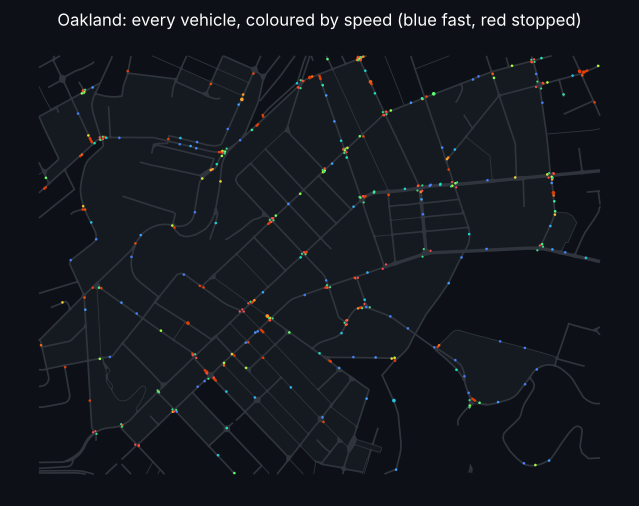

In [3]:
from xnet import network as NW, render as R
net, geo, info = NW.build("oakland")
import jax
one = jax.tree.map(lambda a: np.asarray(a[0]), state)
fig, ax = plt.subplots(figsize=(9, 6), facecolor=R.BG)
ax.set_facecolor(R.GROUND); R.Map(net, geo, info).draw(ax, detail=False, labels=False)
R.snapshot_artists(ax, net, geo, R.Tracks(net, geo), one, False, R.signal_heads(net, geo))
ax.set_aspect("equal"); ax.axis("off"); ax.set_title("Oakland: every vehicle, coloured by speed (blue fast, red stopped)", color="w")
display(fig); plt.close(fig)                                  # xnet.render selects a file backend, so show the figure explicitly

## 3. A question you can answer in minutes: how many AVs until crashes halve?

`examples/av_share_sweep.py` sweeps the AV share with 80 copies per share (~7 min). Here is a 1-minute miniature, then the full
result. Crashes are rare (calibrated humans crash ~15 times per 1,000 vehicle-hours), so the miniature is noisy by design.

0 % AVs      1 crashes in    91 vehicle-hours, 21.2 km/h
100 % AVs    0 crashes in    89 vehicle-hours, 21.5 km/h


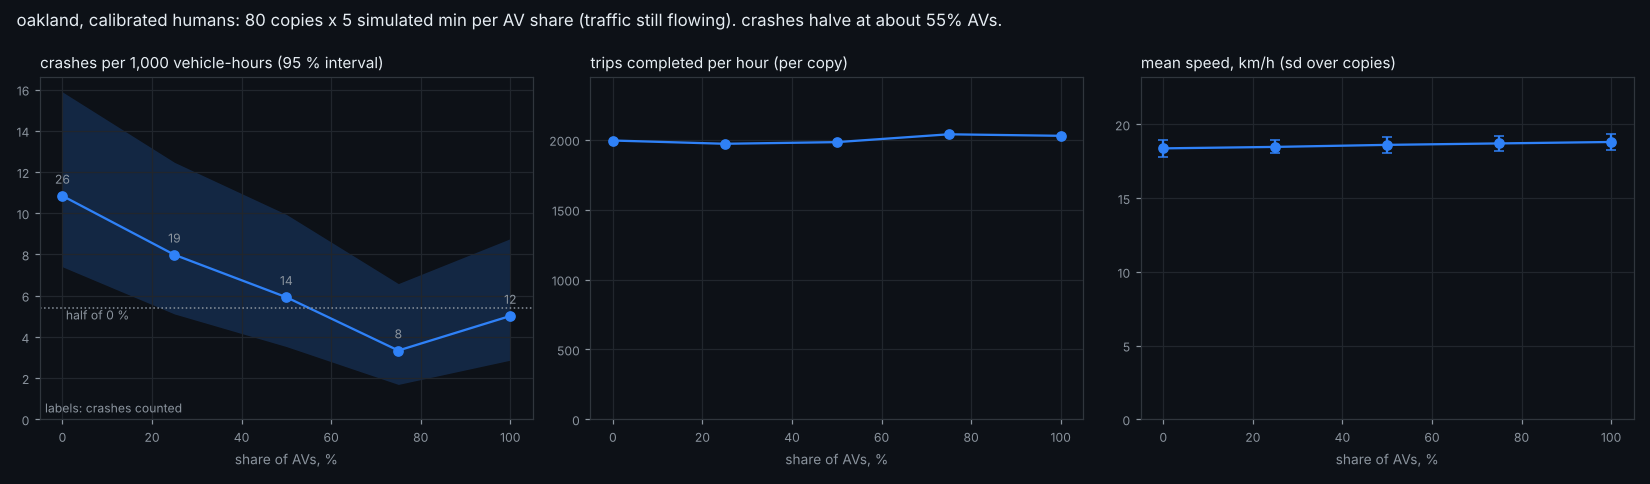

In [4]:
from examples import _common as C
rows = C.per_copy(C.run_copies("oakland", [C.calibrated(p_av=s) for s in (0.0, 1.0) for _ in range(8)], warm_s=60, seconds=180))
for name, g in (("0 % AVs", rows[:8]), ("100 % AVs", rows[8:])):
    vh = sum(r["vehicle_hours"] for r in g); k = sum(r["crashes"] for r in g)
    print(f"{name:10s} {k:3.0f} crashes in {vh:5.0f} vehicle-hours, {np.mean([r['mean_speed_kmh'] for r in g]):.1f} km/h")
display(Image("docs/img/example_av_share.png"))

## 4. Bring your own driver

A policy is any JAX function of the 28 observation features. `examples/my_policy.py` writes the Intelligent Driver Model in 15
lines and scores it on AVBench, the repository's benchmark: the same traffic and random numbers as every leaderboard entry.

In [5]:
from examples.my_policy import careful_idm
from avrl import bench, scorecard as SC
r = bench.evaluate(careful_idm, ["nominal"])
s = r["scenarios"]["nominal"]
print(f"av_world score {s['av_score']:.1f}  (rule-based AV on the same traffic: 72.2)")
print({k: round(v, 3) for k, v in s["metrics"].items() if k in ("crash_per_h_unaided", "comfort_pass", "progress", "filter_share")})
print("fixed bars passed:", {k: v for k, v in SC.absolute_checks(s["metrics"]).items()})

av_world score 81.0  (rule-based AV on the same traffic: 72.2)
{'progress': 0.955, 'comfort_pass': 0.85, 'crash_per_h_unaided': 0.0, 'filter_share': 0.002}
fixed bars passed: {'safer than people': True, 'comfortable': False, 'keeps up': False, 'light touch': True, 'safer unaided': True, 'lawful': True, 'right of way': True, 'inside the barrier': True}


## 5. The whole city's traffic physics

`examples/gridlock.py` raises demand until the network saturates: the fundamental diagram of a street network, with snapshots.

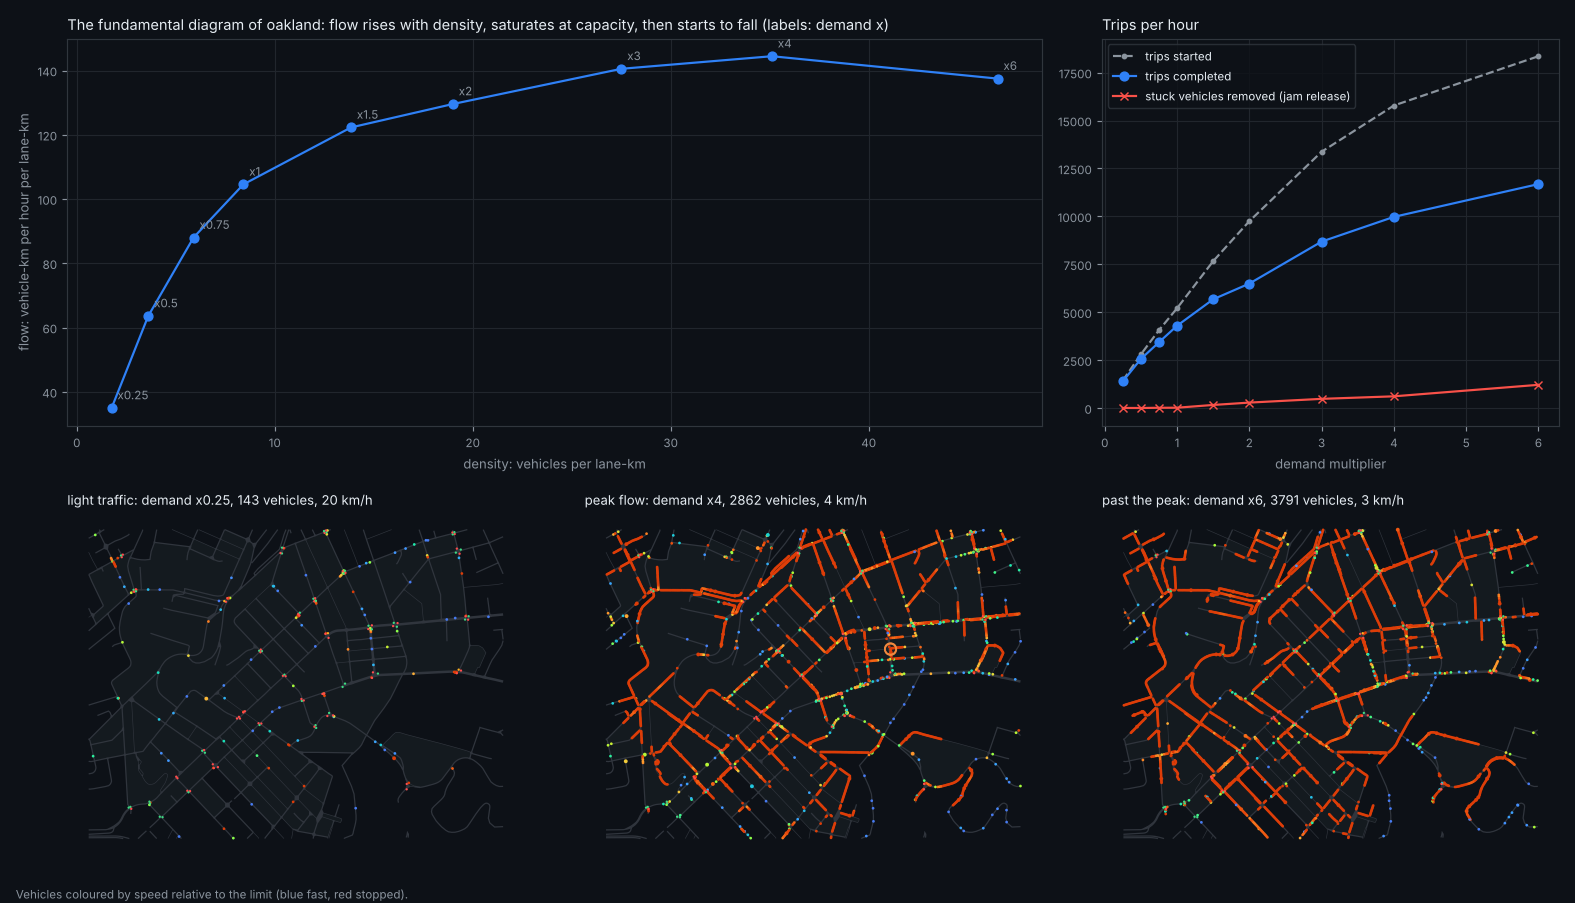

In [6]:
display(Image("docs/img/example_gridlock.png"))

## 6. The long tail, and the rest of the stack

Ten famous AV incident archetypes are built in as scenarios; any of them can be exported as an OpenUSD stage set in the real city,
and an AV crash can be hunted down and filmed (`av-world export-nvidia --find-crash 600`).

In [7]:
from avlab import famous as FM
for name, (what, case, _, counter) in FM.SCENARIOS.items():
    print(f"{name:26s} {what[:90]}")

jaywalker_misclassified    a pedestrian crosses outside the signal phase and the AV's perception drops out while it a
bus_dartout                a pedestrian steps out from in front of a stopped bus or van where cars cannot see
stalled_vehicle_missed     a vehicle is stopped in the lane and the AV's sensor drops it from view while closing
phantom_braking            the AV brakes hard for an obstacle that is not there while traffic follows
sun_glare_blackout         the AV's sensors are blinded for a second or two at a time
aggressive_cut_in          drivers squeeze into a gap far smaller than normal right in front of the AV
red_light_runner           many drivers run the red and enter the junction at speed
unprotected_left           drivers turn across oncoming traffic without looking
cyclist_close_pass         many cyclists, and aggressive overtakers who clip them
black_ice                  the road is slippery: braking distances double


![The same Manhattan scene in av_world and as the exported OpenUSD stage](https://haggler3.github.io/av_world/img/nvidia3d_compare_small.gif)

Camera-only BEV perception (a CPU-sized BEVFormer, `bev/`) trains on rendered views of these cities; held-out Boston results:

bevformer_r50  Boston mAP 0.144  NDS 0.179  (blind: 0.000)
scratch        Boston mAP 0.134  NDS 0.174  (blind: 0.001)


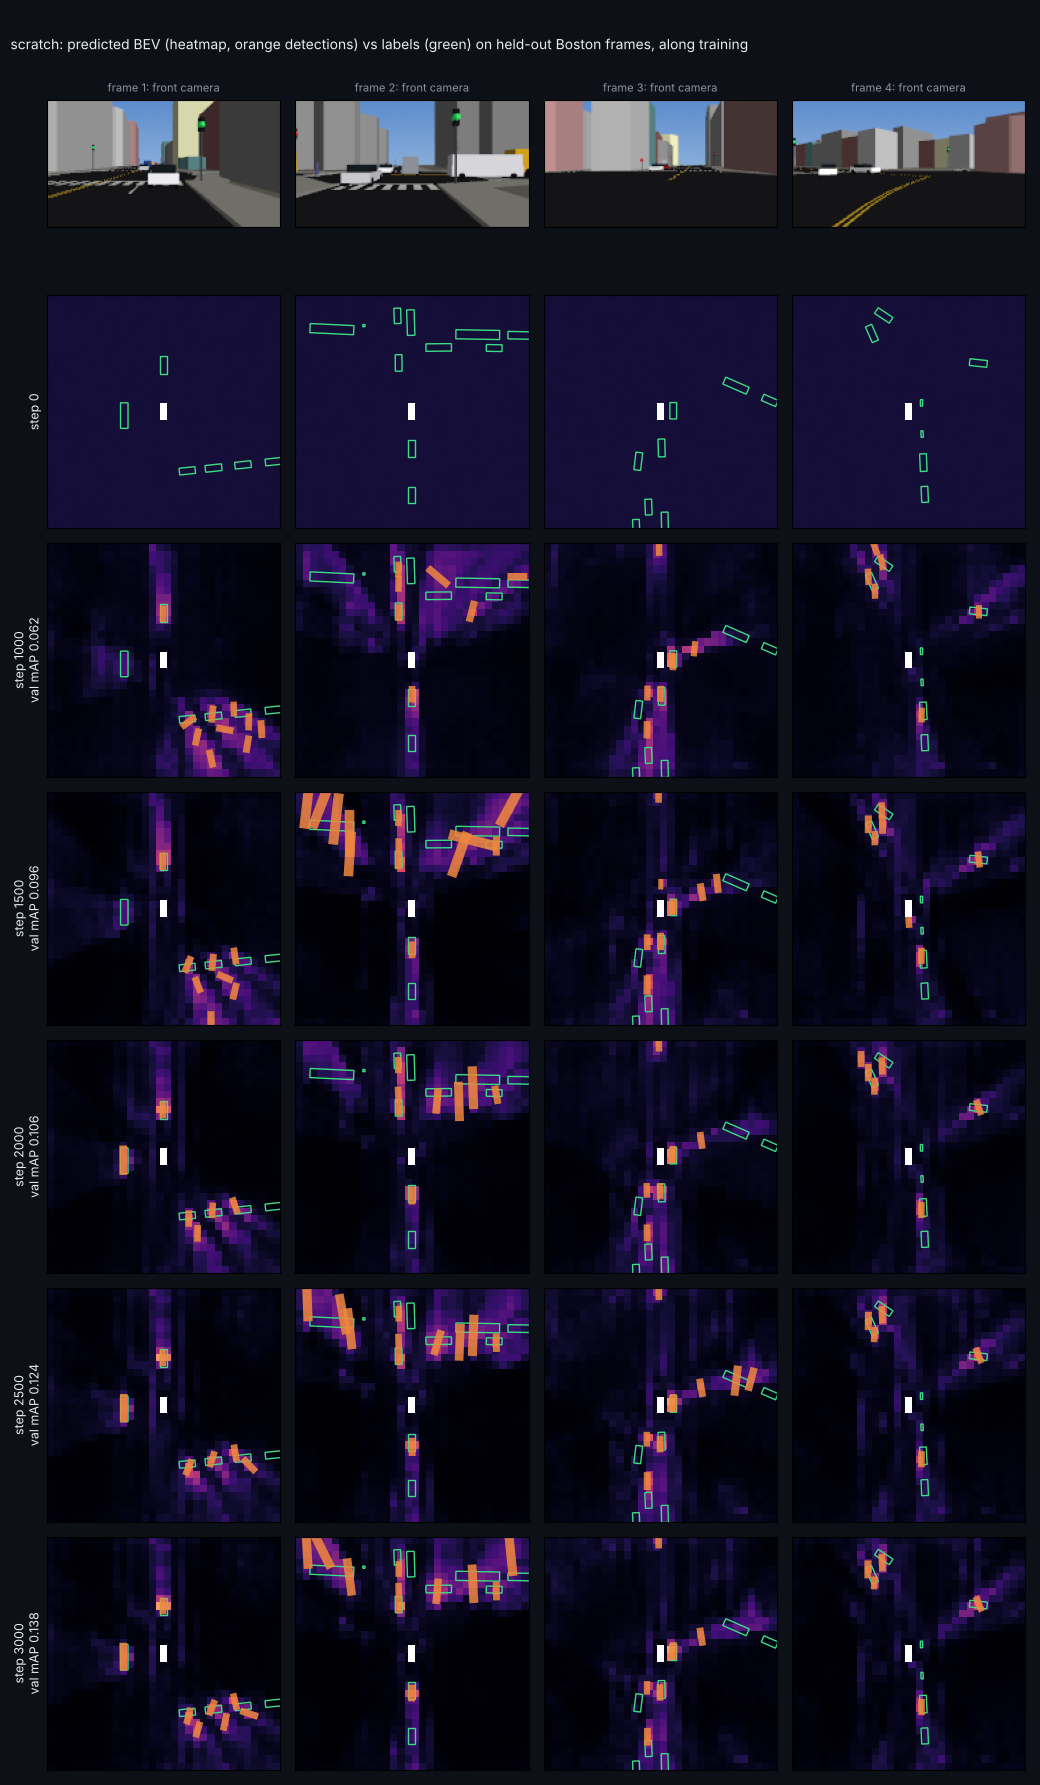

In [8]:
import json
for run in ("bevformer_r50", "scratch"):
    x = json.load(open(f"results/bev/exp_{run}.json"))
    print(f"{run:14s} Boston mAP {x['val']['all']['mAP']:.3f}  NDS {x['val']['all']['NDS']:.3f}  (blind: {x['val_blind']['mAP']:.3f})")
display(Image("docs/img/bev_gallery_scratch.png", width=700))

## 7. Watch it live

In a terminal: `av-world watch oakland` (or `--follow` to ride along with an AV). The same picture, recorded:

![av-world watch oakland](https://haggler3.github.io/av_world/img/watch_oakland.gif)